# Model Building & Training

**XGBoost (Gradient Boosting)** dilatih pada data SMOTE (1:1) dengan **data validation ikut dipantau selama training** (eval log + early stopping); proses training **verbose** ditampilkan per iterasi.

### Install Library

In [28]:
pip install -q xgboost

### Import Library

In [29]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import xgboost as xgb

### Mount Google Drive

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1. Load Processed Data

In [39]:
PROCESSED_DIR = '/content/drive/MyDrive/Fraud Detection/data/processed'
MODELS_DIR = '/content/drive/MyDrive/Fraud Detection/models'
os.makedirs(MODELS_DIR, exist_ok=True)

def load_pkl(filename):
    path = os.path.join(PROCESSED_DIR, filename)
    with open(path, 'rb') as f:
        return pickle.load(f)

X_train_smote = load_pkl('X_train_smote.pkl')
y_train_smote = load_pkl('y_train_smote.pkl')
X_val_scaled = load_pkl('X_val_scaled.pkl')
y_val = load_pkl('y_val.pkl')

y_train_smote = np.asarray(y_train_smote)
y_val = np.asarray(y_val)

### 2. Model Training

In [ ]:
dtrain = xgb.DMatrix(X_train_smote, label=y_train_smote)
dval = xgb.DMatrix(X_val_scaled, label=y_val)

params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 5,
    'eta': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 1,
    'seed': 42,
}

evals_result = {}
booster = xgb.train(
    params,
    dtrain,
    num_boost_round=500,
    evals=[(dtrain, 'train'), (dval, 'valid')],
    evals_result=evals_result,
    early_stopping_rounds=50,
    verbose_eval=True,
)

best_iter = booster.best_iteration
N_TREES = (int(best_iter) + 1) if best_iter is not None else None
print(f'\nBest iteration (validation logloss minimum): {best_iter}')
print(f'N trees dipakai untuk prediksi (best_iteration + 1): {N_TREES}')

FEATURE_NAMES = list(X_train_smote.columns)

def predict_margin(X):
    X_df = pd.DataFrame(np.asarray(X), columns=FEATURE_NAMES)
    d = xgb.DMatrix(X_df)
    if N_TREES is None:
        return booster.predict(d, output_margin=True)
    return booster.predict(d, output_margin=True, iteration_range=(0, N_TREES))

[0]	train-logloss:0.61095	valid-logloss:0.61090
[1]	train-logloss:0.54228	valid-logloss:0.54208
[2]	train-logloss:0.48445	valid-logloss:0.48386
[3]	train-logloss:0.43555	valid-logloss:0.43436
[4]	train-logloss:0.39423	valid-logloss:0.39249
[5]	train-logloss:0.35880	valid-logloss:0.35648
[6]	train-logloss:0.32747	valid-logloss:0.32443
[7]	train-logloss:0.29929	valid-logloss:0.29606
[8]	train-logloss:0.27459	valid-logloss:0.27112
[9]	train-logloss:0.25280	valid-logloss:0.24890
[10]	train-logloss:0.23417	valid-logloss:0.22998
[11]	train-logloss:0.21688	valid-logloss:0.21263
[12]	train-logloss:0.20121	valid-logloss:0.19692
[13]	train-logloss:0.18707	valid-logloss:0.18285
[14]	train-logloss:0.17460	valid-logloss:0.17001
[15]	train-logloss:0.16394	valid-logloss:0.15918
[16]	train-logloss:0.15375	valid-logloss:0.14913
[17]	train-logloss:0.14481	valid-logloss:0.14010
[18]	train-logloss:0.13619	valid-logloss:0.13176
[19]	train-logloss:0.12863	valid-logloss:0.12433
[20]	train-logloss:0.12188	val

### 3. Result

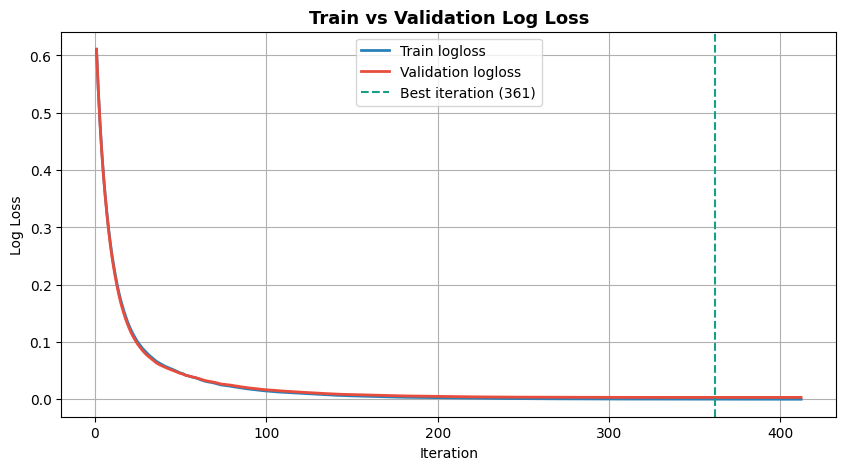

Best Train logloss      : 0.0003
Best Validation logloss : 0.0033
Gap (valid - train)     : 0.0030


In [37]:
train_l = evals_result['train']['logloss']
valid_l = evals_result['valid']['logloss']
best_i = booster.best_iteration

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_l) + 1), train_l, color='#2980b9', lw=2, label='Train logloss')
plt.plot(range(1, len(valid_l) + 1), valid_l, color='#e74c3c', lw=2, label='Validation logloss')
plt.axvline(best_i + 1, color='#16a085', linestyle='--', label=f'Best iteration ({best_i})')
plt.xlabel('Iteration')
plt.ylabel('Log Loss')
plt.title('Train vs Validation Log Loss',
          fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()

print(f'Best Train logloss      : {train_l[best_i]:.4f}')
print(f'Best Validation logloss : {valid_l[best_i]:.4f}')
print(f'Gap (valid - train)     : {valid_l[best_i] - train_l[best_i]:.4f}')

### 4. Save Model

In [ ]:
model_path = os.path.join(MODELS_DIR, 'xgb_model.json')
booster.save_model(model_path)
print(f'Saved: {model_path}')

Saved: /content/drive/MyDrive/Fraud Detection/models/xgb_model.json (n_trees=362)
Verifikasi reload (max diff): 0.00e+00
